# Entregable II — Análisis exploratorio y variables (20 %)

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante
aprendizaje supervisado.  
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.

¿Qué características de una sesión de navegación ayudan a distinguir las visitas
que terminan en compra? Para responder esta pregunta, examinamos la calidad de
los datos, la frecuencia de compra y la distribución de los 17 predictores. Tras
eliminar las sesiones duplicadas, usamos la partición del conjunto de datos
en subconjuntos (entrenamiento, validación y prueba) para medir cuánto distingue
cada variable por sí sola y detectar predictores que aportan información
similar. A partir de estos resultados proponemos qué variables evaluar para su
posible eliminación o combinación en la etapa de modelado.

## Diccionario de variables

Cada fila representa una sesión en la tienda en línea. La tabla describe los 17
predictores y la variable objetivo, `Revenue`, en el orden en que aparecen en el
archivo.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `Administrative` | Conteo | Número de páginas administrativas visitadas. |
| `Administrative_Duration` | Numérica continua | Tiempo total en páginas administrativas, en segundos. |
| `Informational` | Conteo | Número de páginas informativas visitadas. |
| `Informational_Duration` | Numérica continua | Tiempo total en páginas informativas, en segundos. |
| `ProductRelated` | Conteo | Número de páginas de producto visitadas. |
| `ProductRelated_Duration` | Numérica continua | Tiempo total en páginas de producto, en segundos. |
| `BounceRates` | Numérica continua | Tasa media de rebote de las páginas visitadas. Un rebote ocurre cuando el visitante entra por una página y sale sin otra interacción. |
| `ExitRates` | Numérica continua | Tasa media de salida de las páginas visitadas. Para cada página, mide la proporción de vistas en las que esa página fue la última de la sesión. |
| `PageValues` | Numérica continua | Valor medio que Google Analytics atribuye a las páginas visitadas por su contribución a transacciones posteriores. |
| `SpecialDay` | Numérica discreta (ordinal) | Cercanía de la visita al momento esperado de compra para una fecha especial. Toma seis valores de 0 a 1, donde 0 indica que la visita ocurrió fuera de ese período y 1 indica la máxima cercanía. |
| `Month` | Categórica nominal | Mes en el que ocurrió la sesión. |
| `OperatingSystems` | Categórica nominal | Código del sistema operativo del visitante. |
| `Browser` | Categórica nominal | Código del navegador utilizado. |
| `Region` | Categórica nominal | Código de la región geográfica del visitante. |
| `TrafficType` | Categórica nominal | Código de la fuente de tráfico por la que el visitante llegó al sitio. |
| `VisitorType` | Categórica nominal | Tipo de visitante registrado como nuevo, recurrente u otro. |
| `Weekend` | Booleana | Indica si la sesión ocurrió durante el fin de semana. |
| `Revenue` | Booleana (objetivo) | Indica si la sesión terminó en compra (`True`) o sin compra (`False`). |

[Descripción del conjunto de datos en el repositorio de UCI](https://doi.org/10.24432/C5F88Q)

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
SEED = 42

## 1. Carga y auditoría

Empezamos con cargar los datos y hacer una auditoría rápida sobre los mismos,
esto nos permitirá identificar rapidamente problemas con la calidad de los datos
y analizar la distribución de las variables y otros aspectos fundamentales.

In [2]:
# Definimos a partir de la descipción de nuestro dataset cuales son las
# variables nominales, cuales son las numéricas y cual es nuestra variable
# objetivo.

NOMINALES = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
]
NUMERICAS = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
]
BINARIAS = ["Weekend"]
ESPECIALES = ["SpecialDay"]
OBJETIVO = "Revenue"

In [3]:
import platform
from hashlib import sha256

import sklearn
import pandas as pd

def audit(path: str | Path) -> dict:
  """
  Realiza una auditoría sobre el dataset en CSV y devuelve un diccionario
  con información relevante sobre el mismo.
  """
  path = Path(path)
  df = pd.read_csv(path)
  hash = sha256(path.read_bytes()).hexdigest()

  audit_info = {
    "archivo": path.name,
    "hash": hash,
    "filas": df.shape[0],
    "columnas": df.shape[1],
    "nulos": df.isna().sum().sum(),
    "duplicados": df.duplicated().sum(),
    "tipos": {col: str(dtype) for col, dtype in df.dtypes.items()},
    "faltantes_por_columna": {col: int(missing) for col, missing in df.isna().sum().items() if missing > 0},
    "clases": {str(cls): int(count) for cls, count in df[OBJETIVO].value_counts().sort_index().items()},
    "proporcion_compra": float(df[OBJETIVO].mean()),
    "categorias": {
        c: {str(k): int(v) for k, v in df[c].value_counts(dropna=False).items()}
        for c in NOMINALES + BINARIAS + ESPECIALES
      },
    "rango_numericas": {
      c: {
        "min": float(df[c].min()),
        "max": float(df[c].max()),
        "media": float(df[c].mean()),
        "desv": float(df[c].std()),
        "ceros": int((df[c] == 0).sum()),
        "asimetria": float(df[c].skew()),
      }
      for c in NUMERICAS + ESPECIALES
    },
    "valores_especialday": sorted(float(v) for v in df["SpecialDay"].unique()),
    "version_python": platform.python_version(),
    "version_sklearn": sklearn.__version__,
    "semilla": SEED,
  }
  return df, audit_info

In [4]:
df, audit_info = audit(ROOT / "data" / "online_shoppers_intention.csv")

### Resumen de la auditoría

En esta tabla podemos ver un resumen de la auditoría de los datos, con
información como el nombre del archivo y su hash, el número de filas y columnas,
el número de valores nulos, el número de filas duplicadas y la proporción de
entradas cuya intencion de compra es positiva, además de información sobre el
sistema y la versión de Python y de las librerías utilizadas.

In [5]:
pd.Series({
    "Archivo": audit_info["archivo"],
    "SHA-256": audit_info["hash"],
    "Filas": audit_info["filas"],
    "Columnas": audit_info["columnas"],
    "Valores faltantes": audit_info["nulos"],
    "Filas duplicadas": audit_info["duplicados"],
    "Proporción de compra": f"{audit_info['proporcion_compra']:.2%}",
    "Version de Python": audit_info["version_python"],
    "Version de sklearn": audit_info["version_sklearn"],
}, name="Valor").to_frame()

,Valor
Archivo,online_shoppers_intention.csv
SHA-256,d8e130ba51532985f93281a73ce299e6ce150cb915769a...
Filas,12330
Columnas,18
Valores faltantes,0
Filas duplicadas,125
Proporción de compra,15.47%
Version de Python,3.13.5
Version de sklearn,1.7.2


### Tipos de datos y valores faltantes

Similarmente en la siguiente tabla podemos ver los tipos de datos de cada
variable y nuevamente el número de datos nulos. Como podemos apreciar,
aparentemente ninguna columna tiene valores nulos lo cual coincide con el
resultado que obtuvimos anteriormente en _Valores faltantes_.

In [6]:
pd.DataFrame({
    "Tipo": audit_info["tipos"],
    "Faltantes": {col: audit_info["faltantes_por_columna"].get(col, 0)
                  for col in audit_info["tipos"]},
}).rename_axis("Variable")

,Tipo,Faltantes
Variable,,
Administrative,int64,0
Administrative_Duration,float64,0
Informational,int64,0
Informational_Duration,float64,0
ProductRelated,int64,0
ProductRelated_Duration,float64,0
BounceRates,float64,0
ExitRates,float64,0
PageValues,float64,0


### Distribución de clases

La siguiente tabla muestra la distribución de clases de la variable objetivo,
donde claramente se puede ver que la clase positiva es minoritaria (15.47% de
los casos) lo caul es un aspecto importante a tener en cuenta en nuestra fase
de entrenamiento.

In [7]:
pd.Series(audit_info["clases"], name="Sesiones").rename_axis(OBJETIVO).to_frame()

,Sesiones
Revenue,
False,10422
True,1908


### Estadísticas numéricas

Este apartado hace un análisis descriptivo de las variables numéricas, mostrando
estadísticas como la media, mediana, desviación estándar, valores mínimo y
máximo, y la asimetría de la distribución (_skewness_).

In [8]:
pd.DataFrame.from_dict(audit_info["rango_numericas"], orient="index")

,min,max,media,desv,ceros,asimetria
Administrative,0.0,27.000000,2.315166,3.321784,5768,1.960357
Administrative_Duration,0.0,3398.750000,80.818611,176.779107,5903,5.615719
Informational,0.0,24.000000,0.503569,1.270156,9699,4.036464
Informational_Duration,0.0,2549.375000,34.472398,140.749294,9925,7.579185
ProductRelated,0.0,705.000000,31.731468,44.475503,38,4.341516
ProductRelated_Duration,0.0,63973.522230,1194.746220,1913.669288,755,7.263228
BounceRates,0.0,0.200000,0.022191,0.048488,5518,2.947855
ExitRates,0.0,0.200000,0.043073,0.048597,76,2.148789
PageValues,0.0,361.763742,5.889258,18.568437,9600,6.382964
SpecialDay,0.0,1.000000,0.061427,0.198917,11079,3.302667


### Distribución de variables categóricas

Finalmente, se muestra la distribución de las variables categóricas, mostrando
el número de categorias y la frecuencia de cada una de ellas.

In [9]:
SORT_ORDER = {
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep",
            "Oct", "Nov", "Dec"],
  "VisitorType": ["New_Visitor", "Returning_Visitor", "Other"],
  "Weekend": ["True", "False"],
}

for variable, conteos in audit_info["categorias"].items():
  serie = pd.Series(conteos, name="Sesiones").rename_axis(variable)
  if variable in SORT_ORDER:
    orden = [valor for valor in SORT_ORDER[variable] if valor in serie.index]
  else:
    orden = sorted(serie.index, key=float)
  display(serie.reindex(orden).to_frame().T)

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
Sesiones,184,1907,3364,288,432,433,448,549,2998,1727


OperatingSystems,1,2,3,4,5,6,7,8
Sesiones,2585,6601,2555,478,6,19,7,79


Browser,1,2,3,4,5,6,7,8,9,10,11,12,13
Sesiones,2462,7961,105,736,467,174,49,135,1,163,6,10,61


Region,1,2,3,4,5,6,7,8,9
Sesiones,4780,1136,2403,1182,318,805,761,434,511


TrafficType,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Sesiones,2451,3913,2052,1069,260,444,40,343,42,450,247,1,738,13,38,3,1,10,17,198


VisitorType,New_Visitor,Returning_Visitor,Other
Sesiones,1694,10551,85


Weekend,True,False
Sesiones,2868,9462


SpecialDay,0.0,0.2,0.4,0.6,0.8,1.0
Sesiones,11079,178,243,351,325,154


### Análisis de la variable SpecialDay

En la siguiente tabla podemos ver los seis valores que toma `SpecialDay` y el
porcentaje de sesiones que corresponde a cada uno. Es una variable numérica
discreta que indica qué tan cerca estuvo la visita del momento esperado de
compra para una fecha especial. En el 89,85 % de las sesiones el valor es cero
porque la visita ocurrió fuera de esos períodos. En el 10,15 % restante, los
valores van de 0,2 a 1 y un valor mayor indica mayor cercanía.

In [10]:
sesiones = df["SpecialDay"].value_counts().sort_index().rename("Sesiones")
tabla_specialday = sesiones.to_frame()
tabla_specialday["Porcentaje (%)"] = (100 * sesiones / len(df)).round(2)
tabla_specialday

,Sesiones,Porcentaje (%)
SpecialDay,,
0.0,11079,89.85
0.2,178,1.44
0.4,243,1.97
0.6,351,2.85
0.8,325,2.64
1.0,154,1.25


## 2. Distribución de clases

Las barras muestran cuántas sesiones terminaron con y sin compra. El porcentaje sobre cada barra permite comparar ambas clases respecto al total de sesiones.

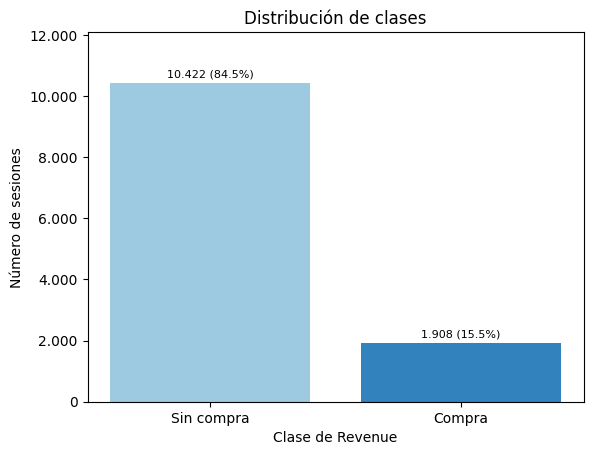

In [11]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

values = df[OBJETIVO].value_counts().sort_index()

fig, ax = plt.subplots()

ax.set_xlabel("Clase de Revenue")
ax.set_ylabel("Número de sesiones")
ax.set_title("Distribución de clases")
bars = ax.bar(["Sin compra", "Compra"], values,
       color=["#9ecae1", "#3182bd"])

conteo = mtick.FuncFormatter(lambda n, _: f"{n:,.0f}".replace(",", "."))
porcentaje = mtick.PercentFormatter(xmax=len(df), decimals=1)
ax.yaxis.set_major_formatter(conteo)
ax.set_ylim(0, max(values) * 1.16)
labels = [f"{conteo(n)} ({porcentaje.format_pct(n, len(df))})" for n in bars.datavalues]
ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

fig.show()

### Cobertura mensual y tasa de compra

Las barras muestran cuántas sesiones corresponden a cada mes. La línea indica el
porcentaje mensual de sesiones con compra. Enero y abril carecen de sesiones,
por lo que su tasa de compra queda sin definir.

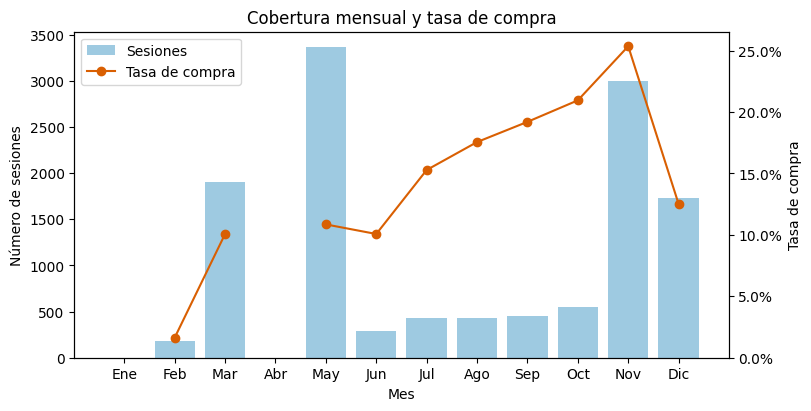

In [12]:
mensual = (
    df.groupby("Month")[OBJETIVO]
    .agg(sesiones="size", tasa_compra="mean")
    .reindex(SORT_ORDER["Month"])
)
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
barras = ax.bar(meses, mensual["sesiones"].fillna(0), color="#9ecae1", label="Sesiones")
ax.set(xlabel="Mes", ylabel="Número de sesiones",
       title="Cobertura mensual y tasa de compra")

ax_tasa = ax.twinx()
linea, = ax_tasa.plot(meses, mensual["tasa_compra"], "o-", color="#d95f02", label="Tasa de compra")
ax_tasa.set_ylabel("Tasa de compra")
ax_tasa.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax_tasa.set_ylim(bottom=0)
ax.legend(handles=[barras, linea], loc="upper left")
plt.show()

## 3. Estadísticas descriptivas

Comparamos la mediana, los cuartiles y el máximo para distinguir el
comportamiento habitual de las sesiones de los valores extremos.

- En las páginas de producto, la mitad de las sesiones acumula como máximo unos
  599 segundos y el 75 % queda por debajo de 1.465 segundos. Sin embargo, el
  máximo alcanza 63.974 segundos y la media sube a 1 195 segundos, casi el doble
  de la mediana.
  
- Esta cola derecha también se observa en el número de páginas de producto
  visitadas, con una mediana de 18 y un máximo de 705.

- Las tasas de rebote y salida, en cambio, toman valores entre 0 y 0,20.

Estas diferencias justifican evaluar dos pasos de preprocesamiento con
propósitos distintos. La transformación opcional `log(1+x)` conserva los ceros y
comprime las diferencias entre valores altos mientras que la estandarización
posterior centra cada variable y la expresa en unidades de desviación estándar
para que magnitudes como los segundos y las tasas sean comparables. La
validación cruzada en entrenamiento permite evaluar si el paso logarítmico
mejora el desempeño.

In [13]:
df[NUMERICAS + ESPECIALES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


## 4. Preparación de los datos

De las 12.330 filas originales, 125 repiten exactamente los valores de una fila
anterior en las 18 columnas. Todas corresponden a observaciones sin compra
(`Revenue = False`) y tienen `BounceRates = 0,2`. Esta variable recoge la tasa
media de rebote de las páginas visitadas.

El archivo carece de un identificador de sesión, por lo que dos visitas
distintas podrían producir registros idénticos. Como criterio de preparación,
conservamos una fila por combinación de valores antes de dividir los datos. Así
evitamos que un registro idéntico aparezca en entrenamiento y en evaluación,
aunque esta decisión puede reducir la representación de visitas legítimas sin
compra.

La primera tabla compara las compras antes y después de la depuración. La
segunda cuenta las combinaciones observadas de `Revenue` y `BounceRates` entre
las filas descartadas. A continuación se muestran las primeras cinco filas
descartadas con su índice original.

In [14]:
# Importar Display
from IPython.display import display

descartar = df.duplicated(keep="first")
descartadas = df.loc[descartar]

resumen = pd.DataFrame({
    etapa: {
        "Filas": len(datos),
        "Sin compra": datos[OBJETIVO].eq(False).sum(),
        "Con compra": datos[OBJETIVO].eq(True).sum(),
        "Compras (%)": round(100 * datos[OBJETIVO].mean(), 2),
    }
    for etapa, datos in {
        "Originales": df, "Descartadas": descartadas, "Conservadas": df.loc[~descartar]
    }.items()
}).T.astype({"Filas": int, "Sin compra": int, "Con compra": int})
display(resumen)

display(descartadas.value_counts([OBJETIVO, "BounceRates"], dropna=False)
        .rename("Filas descartadas").to_frame())

# El índice permite ubicar cada fila en el DataFrame original.
display(descartadas.head())

,Filas,Sin compra,Con compra,Compras (%)
Originales,12330,10422,1908,15.47
Descartadas,125,125,0,0.00
Conservadas,12205,10297,1908,15.63


,,Filas descartadas
Revenue,BounceRates,
False,0.2,125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False


In [15]:
# Guardamos una sola copia de cada fila exacta para las etapas posteriores.
df_deduplicado = df.drop_duplicates(ignore_index=True)
destino = ROOT / "data" / "dataset_deduplicated.pkl"
df_deduplicado.to_pickle(destino)
print(f"{len(df) - len(df_deduplicado)} duplicados eliminados. "
      f"{len(df_deduplicado)} sesiones guardadas en {destino.relative_to(ROOT)}.")

125 duplicados eliminados. 12205 sesiones guardadas en data/dataset_deduplicated.pkl.


## 5. Correlación entre variables numéricas

El mapa muestra la correlación de Pearson entre los predictores numéricos de las
12.205 filas que quedan tras eliminar los duplicados exactos. Dos pares
presentan una correlación positiva superior a 0,8. 

El primero relaciona el número de páginas de producto visitadas
(`ProductRelated`) con el tiempo total en ellas (`ProductRelated_Duration`,
$r = 0{,}860$). Las sesiones con más visitas a páginas de producto tienden a
acumular más tiempo en ellas.

El segundo par corresponde a las tasas medias de rebote y de salida
(`BounceRates` y `ExitRates`, $r = 0{,}902$). Las sesiones que recorren páginas
con tasas de rebote altas suelen presentar también tasas de salida altas.

Si incluimos ambos miembros de un par en una regresión logística, la información
que comparten puede dificultar la interpretación de sus coeficientes por
separado. Para decidir si conviene conservar ambos, podemos comparar en
validación cruzada el modelo que usa el par completo con los que usan cada
variable por separado. El mapa por sí solo describe la relación entre
predictores y deja abierta la pregunta de cuánto aporta cada uno a la predicción
de compra.

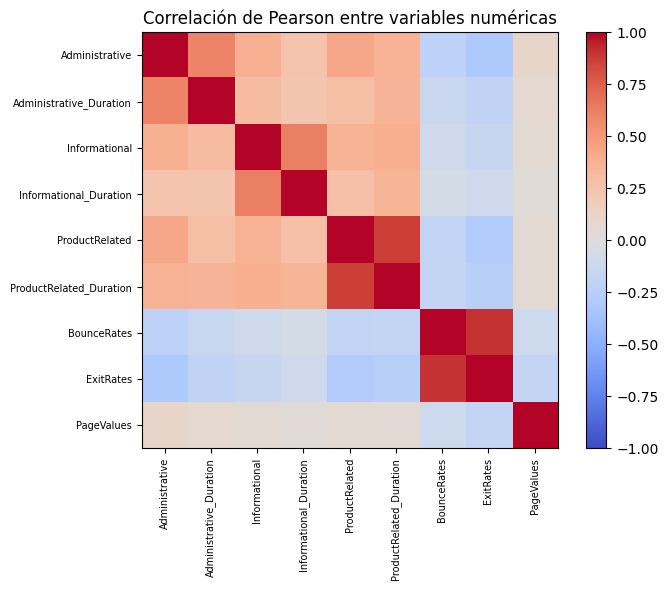

In [16]:
corr = df_deduplicado[NUMERICAS].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title("Correlación de Pearson entre variables numéricas")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 6. Partición de los datos

De las 12.205 filas restantes, destinamos 7.323 al entrenamiento (60 %), 2.441 a
validación (20 %) y 2.441 a prueba (20 %). Primero separamos el entrenamiento y
después dividimos el resto en dos partes iguales. En ambos pasos estratificamos
por `Revenue` para conservar en cada partición una proporción de compras similar
a la del conjunto depurado. Guardamos las particiones con sus valores originales
para ajustar después el preprocesamiento con los datos de entrenamiento.

In [17]:
from sklearn.model_selection import train_test_split

entrenamiento, resto = train_test_split(
    df_deduplicado, test_size=0.40, stratify=df_deduplicado[OBJETIVO], random_state=SEED
)
validacion, prueba = train_test_split(
    resto, test_size=0.50, stratify=resto[OBJETIVO], random_state=SEED
)
particiones = {"entrenamiento": entrenamiento, "validacion": validacion, "prueba": prueba}
ruta_particiones = ROOT / "data" / "dataset_particiones.pkl"
pd.to_pickle(particiones, ruta_particiones)

pd.DataFrame({
    nombre: {"Sesiones": len(datos), "Compras": datos[OBJETIVO].sum(),
             "Compras (%)": round(100 * datos[OBJETIVO].mean(), 2)}
    for nombre, datos in particiones.items()
}).T.astype({"Sesiones": int, "Compras": int}).rename_axis("Partición")

,Sesiones,Compras,Compras (%)
Partición,,,
entrenamiento,7323,1145,15.64
validacion,2441,381,15.61
prueba,2441,382,15.65


## 7. Análisis individual de las 17 variables

En las 7 323 sesiones de entrenamiento medimos cuánto ayuda cada predictor, por separado, a distinguir las sesiones con compra (`Revenue`). Reservamos validación y prueba para evaluar los modelos.

**Variables numéricas.** La correlación punto-biserial ($r$, de −1 a 1) compara el promedio del predictor en sesiones con y sin compra. Un signo positivo indica un promedio mayor entre compradores y uno negativo, menor. Su magnitud refleja esa diferencia respecto a la dispersión del predictor.

**Variables categóricas.** A partir del conteo de sesiones con y sin compra por categoría, la V de Cramér mide la intensidad de la asociación (de 0 a 1). Una V cercana a cero indica tasas de compra similares. Para saber qué categorías tienen tasas mayores, se consultan sus proporciones de compra.

**ROC-AUC univariado.** Mide con qué frecuencia una compra recibe mayor puntaje que una sesión sin compra, contando los empates por mitad. Un AUC de 0,5 equivale al azar y 1 indica separación perfecta. Para las numéricas usamos el sentido que mejor ordena las compras. Para las categóricas dividimos el entrenamiento en cinco pliegues estratificados. Ajustamos la codificación *one-hot* y la regresión logística con cuatro pliegues y puntuamos el quinto. Una vez que cada sesión tiene una probabilidad estimada fuera de su pliegue de ajuste, calculamos un único AUC con todas las predicciones. Para expresar la separación en la escala de 0,5 a 1, reportamos el mayor entre AUC y 1 − AUC.

**Información mutua.** Mide en *nats* cuánto reduce el predictor la incertidumbre sobre la compra, incluso en relaciones no lineales. Un valor cercano a cero indica poca información. La estimamos con vecinos cercanos para las numéricas y con frecuencias conjuntas para las categóricas.

In [18]:
import numpy as np
from scipy.stats import pointbiserialr
from scipy.stats.contingency import association
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder


def analizar_variables(X, y, numericas, categoricas):
    filas = []
    for nombre in numericas:
        valores = X[nombre]
        auc = roc_auc_score(y, valores)
        informacion = mutual_info_classif(X[[nombre]], y, discrete_features=False, random_state=SEED)
        filas.append({
            "variable": nombre,
            "r_punto_biserial": pointbiserialr(y, valores).statistic,
            "auc_univariado": max(auc, 1 - auc),
            "informacion_mutua": informacion[0],
        })

    pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    modelo = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        LogisticRegression(max_iter=2000, solver="lbfgs"),
    )
    for nombre in categoricas:
        conteos = pd.crosstab(X[nombre], y)
        probabilidad = cross_val_predict(
            modelo, X[[nombre]], y, cv=pliegues, method="predict_proba"
        )[:, 1]
        auc = roc_auc_score(y, probabilidad)
        filas.append({
            "variable": nombre,
            "v_cramer": association(conteos.to_numpy(), method="cramer", correction=True),
            "auc_univariado": max(auc, 1 - auc),
            "informacion_mutua": mutual_info_score(None, None, contingency=conteos.to_numpy()),
        })

    columnas = ["variable", "r_punto_biserial", "v_cramer", "auc_univariado", "informacion_mutua"]
    return pd.DataFrame(filas, columns=columnas).sort_values("auc_univariado", ascending=False)

La tabla ordena los predictores por AUC descendente. El guion marca la métrica que no corresponde al tipo de variable.

In [19]:
X_train = entrenamiento.drop(columns=OBJETIVO)
y_train = entrenamiento[OBJETIVO]
analisis = analizar_variables(X_train, y_train, NUMERICAS + ESPECIALES, NOMINALES + BINARIAS)
analisis = analisis.reset_index(drop=True)
analisis.index = pd.RangeIndex(1, len(analisis) + 1, name="ranking")
analisis.style.format(precision=4, na_rep="—")

,variable,r_punto_biserial,v_cramer,auc_univariado,informacion_mutua
ranking,,,,,
1,PageValues,0.4888,—,0.8664,0.1651
2,ExitRates,-0.2104,—,0.7101,0.0429
3,ProductRelated_Duration,0.1418,—,0.6689,0.0317
4,ProductRelated,0.1561,—,0.6582,0.0296
5,Administrative,0.1329,—,0.6258,0.0157
6,TrafficType,—,0.1774,0.6251,0.0161
7,Administrative_Duration,0.0759,—,0.6202,0.0136
8,Month,—,0.1719,0.6160,0.0147
9,BounceRates,-0.1477,—,0.6124,0.0268


### Recomendaciones por variable

El AUC individual orienta la recomendación. Sugerimos mantener desde 0,60, revisar desde 0,55 hasta menos de 0,60 y evaluar la eliminación o combinación por debajo de 0,55. La decisión final depende del aporte conjunto en validación.

1. **`PageValues` — Mantener** (AUC 0,8664). Lidera tanto en AUC como en
  información mutua (0,1651 nats).

2. **`ExitRates` — Mantener** (AUC 0,7101). Las tasas de salida son menores
  entre compradores (r = −0,2104). Ocupa el segundo lugar por AUC.

3. **`ProductRelated_Duration` — Mantener** (AUC 0,6689). Los compradores pasan
  más tiempo en páginas de producto. Su alta correlación con el conteo de
  visitas aconseja evaluar ambos juntos.

4. **`ProductRelated` — Mantener** (AUC 0,6582). Los compradores visitan más
  páginas de producto. El conteo distingue casi tan bien como la duración.

5. **`Administrative` — Mantener** (AUC 0,6258). Los compradores visitan más
  páginas administrativas en promedio (r = 0,1329).

6. **`TrafficType` — Mantener** (AUC 0,6251). Las tasas de compra difieren según
  el origen del tráfico (V = 0,1774). Es la categórica con mayor AUC.

7. **`Administrative_Duration` — Mantener** (AUC 0,6202). El tiempo en páginas
  administrativas distingue las clases pese a la pequeña diferencia entre
  promedios (r = 0,0759).

8. **`Month` — Mantener** (AUC 0,6160). La tasa de compra varía entre los diez
  meses observados (V = 0,1719).

9. **`BounceRates` — Mantener** (AUC 0,6124). Los compradores presentan menores
  tasas de rebote. Su correlación con `ExitRates` aconseja evaluar cuánto añade
  al modelo.

10. **`Informational` — Revisar** (AUC 0,5579). El conteo de páginas informativas
  apenas distingue las clases y aporta poca información (0,0067 nats).

11. **`Informational_Duration` — Revisar** (AUC 0,5563). La duración distingue
  débilmente las clases (r = 0,0658). Podría complementar el conteo de visitas
  informativas.

12. **`OperatingSystems` — Eliminar o combinar** (AUC 0,5436). Las diferencias entre
  sistemas operativos son pequeñas (V = 0,0822) y conviene comprobarlas en
  validación.

13. **`SpecialDay` — Eliminar o combinar** (AUC 0,5388). Los compradores
  presentan menor cercanía media a fechas especiales, con una asociación débil
  (r = −0,0907).

14. **`VisitorType` — Eliminar o combinar** (AUC 0,5375). El tipo de visitante
  muestra cierta asociación (V = 0,0954), aunque su AUC queda por debajo de
  0,55.

15. **`Browser` — Eliminar o combinar** (AUC 0,5153). El navegador distingue
  poco las compras (V = 0,0655) y aporta poca información (0,0022 nats).

16. **`Region` — Eliminar o combinar** (AUC 0,5105). Las tasas de compra varían
  poco entre regiones (V = 0,0355).

17. **`Weekend` — Eliminar o combinar** (AUC 0,5038). El fin de semana tiene el
  AUC más cercano al azar y la menor información mutua (0,0002 nats).

### Pares de predictores con alta correlación

Para comprobar si las relaciones observadas en la sección 5 se mantienen en las
7.323 sesiones de entrenamiento, calculamos la correlación de Pearson entre los
predictores numéricos. La tabla muestra una sola vez cada par con
$|r| \geq 0{,}8$, umbral que usamos para identificar variables que podrían
aportar información similar al modelo.

In [20]:
def pares_redundantes(X, numericas):
    correlaciones = X[numericas].corr()
    superior = np.triu(np.ones(correlaciones.shape, dtype=bool), k=1)
    pares = correlaciones.where(superior).rename_axis(
        index="variable_1", columns="variable_2"
    ).stack()
    return pares[pares.abs() >= 0.8].reset_index(name="correlacion")


redundancia = pares_redundantes(X_train, NUMERICAS)
redundancia.round(4)

,variable_1,variable_2,correlacion
0,ProductRelated,ProductRelated_Duration,0.8426
1,BounceRates,ExitRates,0.8990


En entrenamiento, los mismos dos pares superan el umbral. El número de páginas
de producto visitadas y el tiempo total en ellas aumentan juntos
($r = 0{,}8426$). La asociación es aún mayor entre las tasas medias de rebote y
de salida ($r = 0{,}8990$).

El conteo y la duración tienen AUC individuales cercanos (0,6582 y 0,6689). En
cambio, la tasa de salida distingue mejor las compras que la de rebote (0,7101
frente a 0,6124). Para determinar si conviene conservar ambos miembros de cada
par, se puede comparar en los mismos pliegues de validación cruzada el modelo
completo con dos variantes que omitan, por separado, uno de los predictores.

## 7. Conclusiones

Hubo 1.908 compras en 12.330 sesiones (15,47 %) repartidas en diez meses. La auditoría identificó 125 filas duplicadas y ningún valor faltante. Tras la depuración, la estratificación mantuvo proporciones de compra similares en las tres particiones.

En entrenamiento, `PageValues` lidera en AUC (0,8664) e información mutua (0,1651 nats). Le sigue `ExitRates` en AUC (0,7101), mientras que `Weekend` apenas distingue las clases (0,5038). Los conteos y tiempos en páginas de producto se solapan, al igual que las tasas de rebote y salida. Seis predictores quedan por debajo del umbral de 0,55: `OperatingSystems`, `SpecialDay`, `VisitorType`, `Browser`, `Region` y `Weekend`. En la siguiente etapa se podrá evaluar su eliminación en conjunto, tomando como referencia el modelo con los 17 predictores.

## Resultados para la validación cruzada

Guardamos en `resultados/variables/` el ranking y la recomendación de cada predictor (`analisis_variables.json`), y los pares con correlación absoluta de al menos 0,80 en entrenamiento (`redundancia_numericas.json`). El siguiente notebook puede leer estos archivos junto con las particiones guardadas en `data/dataset_particiones.pkl`.

In [21]:
salida = ROOT / "resultados" / "variables"
salida.mkdir(parents=True, exist_ok=True)

variables = analisis.reset_index()
variables["recomendacion"] = np.select(
    [variables["auc_univariado"] >= 0.60, variables["auc_univariado"] >= 0.55],
    ["mantener", "revisar"],
    default="eliminar o combinar",
)
for nombre, tabla in [
    ("analisis_variables", variables),
    ("redundancia_numericas", redundancia),
]:
    tabla.to_json(
        salida / f"{nombre}.json", orient="records", force_ascii=False,
        indent=2, double_precision=15,
    )